# 06 - Failure Investigator
Seed-0 test set of Titanic (179 passengers). Where do models agree, where do they fail, and what do they rely on?

In [1]:
import sys, json; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from arena.config import RAW_DIR, SUMMARY_DIR, PRED_DIR, FIG_DIR
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
cases = pd.read_csv(SUMMARY_DIR/'failures_clf_cases.csv')
cm = pd.read_csv(SUMMARY_DIR/'failures_clf_confusion.csv')
sub = pd.read_csv(SUMMARY_DIR/'failures_clf_subgroups.csv')
imp = pd.read_csv(SUMMARY_DIR/'failures_importance_clf.csv')
models = [c[:-5] for c in cases.columns if c.endswith('_pred')]
print(models)

['dt', 'id3', 'dt_disc', 'knn', 'nc', 'ann', 'rf', 'ada', 'xgb']


## 1. Agreement structure
`hard_core` = every model is wrong; `contested` = models split; `all_correct`.

In [2]:
cases.category.value_counts().to_frame('passengers').assign(share=lambda d: (d.passengers/d.passengers.sum()).round(3))

,passengers,share
category,,
all_correct,110,0.615
contested,56,0.313
hard_core,13,0.073


### Hard-core failures (all models wrong), with raw features

In [3]:
cols = ['row_id','y_true','Pclass','Sex','Age','Fare','Embarked','Title','FamilySize','n_wrong']
cases[cases.category=='hard_core'][cols]

,row_id,y_true,Pclass,Sex,Age,Fare,Embarked,Title,FamilySize,n_wrong
0,283,1,3,male,19.0,8.0500,S,Mr,1,9
1,207,1,3,male,26.0,18.7875,C,Mr,1,9
2,569,1,3,male,32.0,7.8542,S,Mr,1,9
3,36,1,3,male,NaN,7.2292,C,Mr,1,9
4,267,1,3,male,25.0,7.7750,S,Mr,2,9
5,288,1,2,male,42.0,13.0000,S,Mr,1,9
6,301,1,3,male,NaN,23.2500,Q,Mr,3,9
7,498,0,1,female,25.0,151.5500,S,Mrs,4,9
8,510,1,3,male,29.0,7.7500,Q,Mr,1,9
9,543,1,2,male,32.0,26.0000,S,Mr,2,9


### Most contested passengers (models split about evenly)

In [4]:
c = cases[cases.category=='contested'].assign(split=lambda d: (d.n_wrong - len(models)/2).abs()).sort_values('split').head(10)
c[cols]

,row_id,y_true,Pclass,Sex,Age,Fare,Embarked,Title,FamilySize,n_wrong
28,483,1,3,female,63.0,9.5875,S,Mrs,1,5
27,882,0,3,female,22.0,10.5167,S,Miss,1,5
34,92,0,1,male,46.0,61.1750,S,Mr,2,4
33,826,0,3,male,NaN,56.4958,S,Mr,1,4
32,402,0,3,female,21.0,9.8250,S,Miss,2,4
31,276,0,3,female,45.0,7.7500,S,Miss,1,4
30,113,0,3,female,20.0,9.8250,S,Miss,2,4
29,132,0,3,female,47.0,14.5000,S,Mrs,2,5
36,328,1,3,female,31.0,20.5250,S,Mrs,3,4
35,434,0,1,male,50.0,55.9000,S,Mr,2,4


## 2. Confusion matrices per model (rows = true, columns = predicted; 1 = survived)

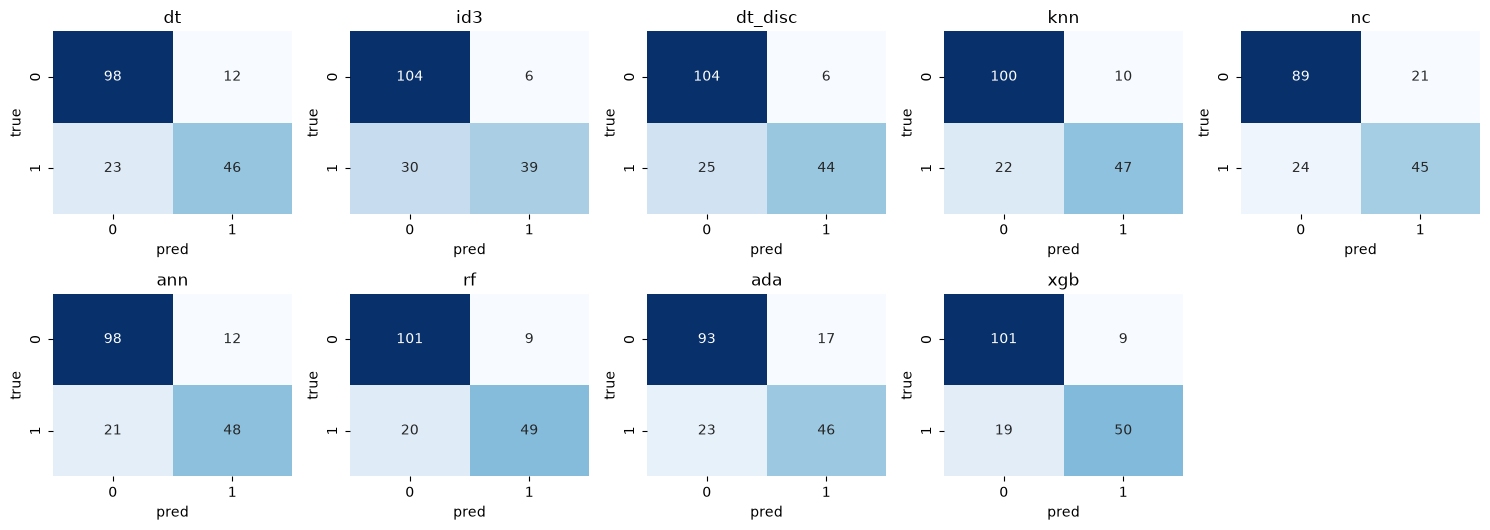

In [5]:
n = len(models); fig, axes = plt.subplots(2, (n+1)//2, figsize=(3*((n+1)//2), 5.4)); axes = axes.ravel()
for ax, m in zip(axes, models):
    t = cm[cm.model==m].pivot(index='true', columns='pred', values='count'); sns.heatmap(t, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax); ax.set_title(m)
for ax in axes[n:]: ax.axis('off')
plt.tight_layout(); plt.savefig(FIG_DIR/'confusion_matrices.png', dpi=130); plt.show()

## 3. Error rate by subgroup

In [6]:
sub.pivot_table(index=['group','value'], columns='model', values='error_rate').round(2).join(sub.drop_duplicates(['group','value']).set_index(['group','value']).n)

ada   ann    dt  dt_disc   id3   knn    nc    rf   xgb    n
group   value                                                                
AgeBand adult    0.26  0.22  0.24     0.17  0.21  0.18  0.24  0.17  0.16  119
        child    0.21  0.14  0.14     0.21  0.36  0.21  0.29  0.14  0.07   14
        senior   0.20  0.00  0.00     0.20  0.00  0.00  0.40  0.20  0.20    5
        teen     0.20  0.20  0.20     0.20  0.10  0.30  0.10  0.20  0.20   10
        unknown  0.10  0.10  0.10     0.16  0.16  0.13  0.29  0.13  0.16   31
Pclass  1        0.28  0.21  0.26     0.21  0.21  0.21  0.26  0.16  0.21   43
        2        0.12  0.06  0.06     0.06  0.06  0.09  0.15  0.06  0.06   34
        3        0.24  0.22  0.22     0.20  0.25  0.20  0.28  0.20  0.17  102
Sex     female   0.24  0.21  0.24     0.16  0.25  0.19  0.29  0.16  0.11   63
        male     0.22  0.17  0.17     0.18  0.17  0.17  0.23  0.16  0.18  116

## 4. What do models rely on? Permutation importance (test set, drop in macro-F1) vs. native importance

In [7]:
p = imp.pivot(index='feature', columns='model', values='perm_importance').round(3); display(p.sort_values('xgb', ascending=False))
nat = imp.pivot(index='feature', columns='model', values='native_importance').dropna(axis=1, how='all').round(3); display(nat)

model,ann,dt,knn,rf,xgb
feature,,,,,
Title,0.060,0.292,0.086,0.058,0.187
Pclass,0.024,0.006,0.092,0.040,0.083
Sex,0.110,0.000,0.092,0.148,0.052
Age,0.022,0.000,0.055,0.034,0.045
Fare,0.005,0.000,0.030,0.035,0.043
Embarked,0.005,0.000,0.014,0.023,0.016
Parch,0.018,0.000,0.007,-0.004,0.003
IsAlone,0.035,0.000,0.016,0.004,0.000
SibSp,0.019,0.000,0.020,0.003,-0.001


model,dt,rf,xgb
feature,,,
Age,0.000,0.099,0.015
Embarked,0.000,0.030,0.047
FamilySize,0.105,0.053,0.039
Fare,0.110,0.158,0.026
IsAlone,0.000,0.011,0.000
Parch,0.000,0.015,0.013
Pclass,0.139,0.096,0.099
Sex,0.000,0.279,0.089
SibSp,0.000,0.037,0.021


In [8]:
print('Spearman rank agreement of permutation importance between models:'); display(imp.pivot(index='feature', columns='model', values='perm_importance').corr(method='spearman').round(2))
from scipy.stats import spearmanr
for m in nat.columns:
    print(m, 'permutation vs native rank agreement: %.2f' % spearmanr(p[m], nat[m])[0])

Spearman rank agreement of permutation importance between models:


model,ann,dt,knn,rf,xgb
model,,,,,
ann,1.00,0.07,0.67,0.64,0.61
dt,0.07,1.00,0.23,0.20,0.28
knn,0.67,0.23,1.00,0.90,0.82
rf,0.64,0.20,0.90,1.00,0.88
xgb,0.61,0.28,0.82,0.88,1.00


dt permutation vs native rank agreement: 0.81
rf permutation vs native rank agreement: 0.83
xgb permutation vs native rank agreement: 0.65


## 5. ID3 learned tree (from-scratch implementation, discretized features)

In [9]:
from arena.evaluate import split
from arena.preprocess import Discretizer
from arena.id3 import ID3Classifier
Xtr, Xte, ytr, yte = split('clf', 0)
d = Discretizer().fit(Xtr); m = ID3Classifier(max_depth=3).fit(d.transform(Xtr), ytr)
print(m.export_text(list(d.cols_), ['died','survived'])); print('test acc: %.3f' % (m.predict(d.transform(Xte)) == yte).mean())

Title = 0
    SibSp = 0
        -> survived
    SibSp = 1
        -> survived
    SibSp = 2
        -> survived
    SibSp = 3
        Parch = 1
            -> died
        Parch = 2
            -> died
Title = 1
    Pclass = 0
        Fare = 2
            -> survived
        Fare = 3
            -> survived
    Pclass = 1
        Age = 0
            -> survived
        Age = 1
            -> survived
        Age = 2
            -> survived
        Age = 3
            -> survived
    Pclass = 2
        Fare = 0
            -> survived
        Fare = 1
            -> died
        Fare = 2
            -> died
        Fare = 3
            -> died
Title = 2
    Pclass = 0
        Fare = 0
            -> died
        Fare = 2
            -> died
        Fare = 3
            -> died
    Pclass = 1
        Fare = 0
            -> died
        Fare = 1
            -> died
        Fare = 2
            -> died
        Fare = 3
            -> died
    Pclass = 2
        Fare = 0
            -> die

## 6. Regression failures (California, seed 0)

In [10]:
rng = pd.read_csv(SUMMARY_DIR/'failures_reg_by_range.csv')
display(rng.pivot(index='target_range', columns='model', values='mae').round(3))
display(rng.pivot(index='target_range', columns='model', values='mean_residual').round(3))

model,dt,gb,lin,rf,xgb
target_range,,,,,
1-2,0.332,0.246,0.447,0.264,0.232
2-3,0.447,0.330,0.368,0.342,0.310
3-4,0.598,0.451,0.697,0.501,0.442
4-5,0.769,0.633,1.252,0.697,0.595
<1,0.263,0.210,0.465,0.221,0.192
capped(5.0),0.774,0.617,1.548,0.711,0.572


model,dt,gb,lin,rf,xgb
target_range,,,,,
1-2,-0.175,-0.122,-0.311,-0.169,-0.109
2-3,0.007,0.008,0.051,-0.002,0.007
3-4,0.287,0.216,0.646,0.277,0.176
4-5,0.607,0.505,1.213,0.572,0.455
<1,-0.223,-0.161,-0.336,-0.195,-0.144
capped(5.0),0.774,0.553,1.199,0.711,0.502


`mean_residual = actual - predicted`: positive = under-prediction. The `capped(5.0)` row shows the ceiling effect: true prices are cut at $500k so models cannot learn them.

In [11]:
w = pd.read_csv(SUMMARY_DIR/'failures_reg_worst.csv'); w.head(10).round(2)

,row_id,y_true,xgb_pred,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,abs_error
0,6651,5.00,1.87,1.99,41.0,3.28,1.06,855.0,2.23,34.15,-118.14,3.13
1,4861,5.00,1.94,0.50,29.0,2.37,1.06,2690.0,12.40,34.02,-118.28,3.06
2,489,4.90,1.88,3.04,48.0,4.69,1.13,1656.0,3.61,37.86,-122.25,3.01
3,17330,0.84,3.57,2.89,11.0,7.92,1.69,317.0,4.28,34.61,-120.09,2.73
4,10574,5.00,2.31,1.97,6.0,4.80,1.16,125.0,2.84,33.72,-117.70,2.69
5,6226,1.82,4.46,9.71,38.0,8.75,1.10,129.0,6.45,34.07,-117.92,2.64
6,16642,5.00,2.46,0.70,19.0,2.43,1.13,1799.0,2.83,35.30,-120.67,2.54
7,14431,1.94,4.26,3.55,20.0,5.66,1.66,615.0,1.89,32.80,-117.28,2.32
8,4630,5.00,2.68,2.37,20.0,2.74,1.05,2919.0,2.45,34.07,-118.31,2.32
9,13979,0.42,2.70,0.54,4.0,14.00,3.33,9.0,3.00,34.14,-116.76,2.28


In [12]:
impr = pd.read_csv(SUMMARY_DIR/'failures_importance_reg.csv'); impr.pivot(index='feature', columns='model', values='perm_importance').round(3).sort_values('xgb', ascending=False)

model,gb,lin,rf,xgb
feature,,,,
Latitude,1.107,0.739,0.380,0.992
Longitude,1.024,0.701,0.311,0.899
MedInc,0.485,0.613,0.623,0.400
AveOccup,0.170,0.010,0.208,0.174
AveRooms,0.066,0.064,0.034,0.100
HouseAge,0.054,0.019,0.085,0.064
AveBedrms,0.021,0.086,0.013,0.015
Population,0.004,-0.000,0.007,0.012


## 7. Trade-off: accuracy vs. robustness vs. complexity vs. cost

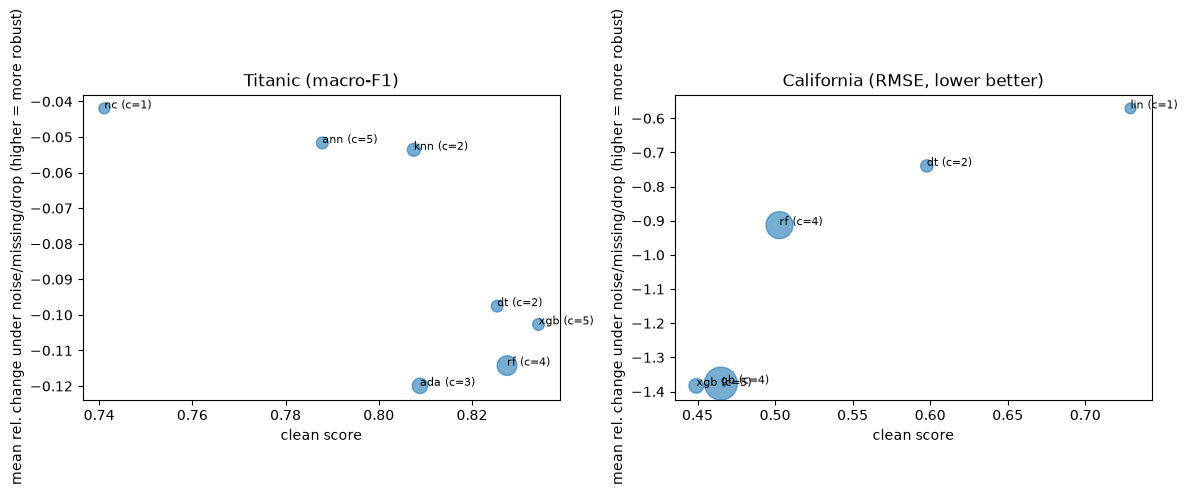

,model,score,score_std,fit_time_s,complexity,relchg_drop_feature,relchg_imbalance,relchg_imbalance_matched,relchg_missing,relchg_noise,feature_robustness
0,xgb,0.834,0.017,0.455,5,-0.190,-0.173,0.028,-0.072,-0.047,-0.103
1,rf,0.828,0.007,5.665,4,-0.315,-0.221,0.012,-0.018,-0.010,-0.114
2,dt,0.825,0.025,0.479,2,-0.207,-0.190,-0.013,-0.044,-0.042,-0.098
4,ada,0.809,0.028,2.525,3,-0.324,-0.206,0.014,-0.014,-0.022,-0.120
5,knn,0.808,0.014,1.097,2,-0.108,-0.341,-0.152,-0.031,-0.022,-0.054
7,ann,0.788,0.052,0.543,5,-0.098,-0.330,-0.133,-0.040,-0.018,-0.052
8,nc,0.741,0.034,0.092,1,-0.098,-0.031,-0.020,-0.021,-0.006,-0.042


,model,score,score_std,fit_time_s,complexity,relchg_drop_feature,relchg_missing,relchg_noise,feature_robustness
0,xgb,0.449,0.008,2.064,5,-1.350,-1.091,-1.710,-1.383
1,gb,0.465,0.005,51.246,4,-1.330,-0.990,-1.811,-1.377
2,rf,0.503,0.009,12.711,4,-1.049,-0.601,-1.088,-0.913
3,dt,0.598,0.014,0.777,2,-0.873,-0.436,-0.909,-0.739
4,lin,0.729,0.004,0.009,1,-0.759,-0.463,-0.491,-0.571


In [13]:
tc = pd.read_csv(SUMMARY_DIR/'tradeoff_clf.csv').dropna(subset=['feature_robustness']); tr = pd.read_csv(SUMMARY_DIR/'tradeoff_reg.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t, ttl in zip(axes, [tc, tr], ['Titanic (macro-F1)', 'California (RMSE, lower better)']):
    ax.scatter(t.score, t.feature_robustness, s=60 + 25*t.fit_time_s.clip(upper=20), alpha=.6)
    for r in t.itertuples(): ax.annotate(f'{r.model} (c={r.complexity})', (r.score, r.feature_robustness), fontsize=8)
    ax.set_xlabel('clean score'); ax.set_ylabel('mean rel. change under noise/missing/drop (higher = more robust)'); ax.set_title(ttl)
plt.tight_layout(); plt.savefig(FIG_DIR/'tradeoff.png', dpi=130); plt.show()
display(tc.round(3)); display(tr.round(3))

In [14]:
# Data-driven summary (no hand-written numbers)
best = tc.sort_values('score').iloc[-1]; most_rob = tc.sort_values('feature_robustness').iloc[-1]
print(f"Titanic: best clean model = {best.model} ({best.score:.3f}); most feature-robust = {most_rob.model} ({most_rob.feature_robustness:+.3f}, clean score {most_rob.score:.3f}).")
br = tr.sort_values('score').iloc[0]; mr = tr.sort_values('feature_robustness').iloc[-1]
print(f"California: best clean model = {br.model} (RMSE {br.score:.3f}); most feature-robust = {mr.model} ({mr.feature_robustness:+.2f}, RMSE {mr.score:.3f}).")

Titanic: best clean model = xgb (0.834); most feature-robust = nc (-0.042, clean score 0.741).
California: best clean model = xgb (RMSE 0.449); most feature-robust = lin (-0.57, RMSE 0.729).
